# Recipe clustering (HDBSCAN)

Features per Food.com recipe (`input_stage2/foodcom_recipes.csv`, one row per recipe):
- **product** embedding (mean of lemmatized product phrases, over all its ingredients), block weight **1.5×**
- **adj + verb** embedding (mean of lemmatized descriptor tokens)
- **tags** embedding (mean of the recipe's Food.com tags, leaving out the category headers most recipes carry)
- **nutrients** per 100 g (log1p, standardized): Food.com's per-serving values, divided by the serving's grams
- **total price** as an interval: `total_price` (the sum of the priced ingredients), **±3 per unpriced ingredient** → `[price_lo, price_hi]`

Each block is scaled to unit total variance before weighting, so the weights mean what they say regardless of dimensionality.
Pipeline: features → UMAP (10-d) → HDBSCAN, with a 2-d UMAP used only for plotting.

In [32]:
import ast, re, os, json, hashlib
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.stem import WordNetLemmatizer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import HDBSCAN
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sentence_transformers import SentenceTransformer
import umap

SEED = 42
UNPRICED_BAND = 3.0      # ± per unpriced item
WEIGHTS = {'product': 1.5, 'adj_verb': 1.0, 'tags': 1.0, 'nutrients': 1.0, 'price': 1.0}
PCA_DIMS = {'product': 32, 'adj_verb': 16, 'tags': 16}     # blocks not listed are used as-is
ENCODER_NAME = 'Qwen/Qwen3-Embedding-0.6B'
# a tag on more than this share of the training recipes is a Food.com category header ("preparation", "course"),
# not a trait of the recipe, and is left out of the tags embedding
GENERIC_TAG_SHARE = 0.6
# its own directory: model_artifacts/recipe_clustering is the FDC model of recipe_clustering.ipynb, which the API loads
ARTIFACT_DIR = 'model_artifacts/recipe_clustering_foodcom'
# Food.com has no fiber or cholesterol
NUTRIENTS = ['protein_g', 'fat_g', 'carb_g', 'energy_kcal', 'sodium_mg', 'satfat_g', 'sugars_g']
# foodcom_recipes.csv column -> (nutrient, divisor back to Food.com's value per serving). Food.com gives calories in
# kcal and the rest as % of a daily value; the CSV multiplied each by its daily value (2000 kcal, 65 g fat, 50 g sugar,
# 2400 mg sodium, 50 g protein, 20 g saturated fat, 300 g carbs) without dividing by 100, and calories by 2000 though
# they were kcal already. Checked against RAW_recipes.csv: every column is exactly the raw value times that factor.
FOODCOM_NUTRIENTS = {
    'calories (g)': ('energy_kcal', 2000),      # kcal
    'total fat (g)': ('fat_g', 100),
    'sugar (g)': ('sugars_g', 100),
    'sodium (g)': ('sodium_mg', 100),           # mg
    'protein (g)': ('protein_g', 100),
    'saturated fat (g)': ('satfat_g', 100),
    'carbohydrates (g)': ('carb_g', 100),
}

for pkg in ['wordnet', 'omw-1.4']:
    nltk.download(pkg, quiet=True)

LIST_COLS = ['product', 'unpriced_items', 'adj', 'verb']
# written as JSON (null for an unpriced ingredient), which literal_eval cannot read; tags are a JSON list of strings
JSON_COLS = ['price_breakdown', 'tags']

def parse_lists(frame):
    frame = frame.copy()
    for c in LIST_COLS:
        frame[c] = frame[c].apply(lambda v: ast.literal_eval(v) if isinstance(v, str) else v)
    for c in JSON_COLS:
        frame[c] = frame[c].apply(lambda v: json.loads(v) if isinstance(v, str) else v)
    return frame

def add_nutrients(frame):
    # per serving, then per 100 g by the serving's grams ("1 (129 g)"); a serving of unknown or 0 g is left NaN,
    # which raw_blocks fills with the median
    grams = frame['serving_size'].astype(str).str.extract(r'\((\d+(?:\.\d+)?)\s*g\)')[0].astype(float)
    grams = grams.where(grams > 0)
    for column, (name, divisor) in FOODCOM_NUTRIENTS.items():
        frame[name] = frame[column] / divisor / grams * 100
    return frame

df = add_nutrients(parse_lists(pd.read_csv('../../input_stage2/foodcom_recipes.csv')))
df.shape

(218691, 31)

In [33]:
df

,recipe_id,calories (g),total fat (g),sugar (g),sodium (g),protein (g),saturated fat (g),carbohydrates (g),product,adj,...,price_coverage,priced_items,unpriced_items,energy_kcal,fat_g,sugars_g,sodium_mg,protein_g,satfat_g,carb_g
0,137739,103000.0,0.0,650.0,0.0,100.0,0.0,1200.0,"[[winter squash], [mexican seasoning], [mixed ...","[[], [], [], [], [], [], []]",...,partial,"['olive oil', 'winter squash', 'salt', 'butter']","[honey, mexican seasoning, mixed spice]",39.922481,0.000000,5.038760,0.000000,0.775194,0.000000,9.302326
1,31490,346800.0,1170.0,0.0,40800.0,1100.0,700.0,300.0,"[[pizza], [sausage patty], [egg], [milk], [sal...","[[], [], [], [], [], []]",...,partial,"['eggs', 'prepared pizza crust', 'milk', 'chee...","[sausage patty, salt and pepper]",208.915663,14.096386,0.000000,491.566265,13.253012,8.433735,3.614458
2,112140,539600.0,1430.0,1600.0,115200.0,1950.0,540.0,1500.0,"[[beef], [onion], [tomato], [tomato paste], [s...","[[], [yellow], [], [], [tomato], [], [], [], [...",...,partial,"['kidney beans', 'diced tomatoes', 'tomato sou...","[cheddar cheese, tomato paste, rotel tomatoes,...",76.214689,4.039548,4.519774,325.423729,5.508475,1.525424,4.237288
3,59389,736200.0,1105.0,500.0,4800.0,700.0,160.0,6000.0,"[[spreadable, cheese, garlic, herb], [new pota...","[[], [], [], [], [], [], [red], [], [], [red],...",...,partial,"['olive oil', 'salt', 'parsley', 'pepper', 'sh...","[red bell pepper, new potatoes, red wine vineg...",128.257840,3.850174,1.742160,16.724739,2.439024,0.557491,20.905923
4,44061,705800.0,65.0,16850.0,55200.0,150.0,0.0,8400.0,"[[tomato juice], [apple cider vinegar], [sugar...","[[], [], [], [], [], [], [], []]",...,partial,"['sugar', 'pepper', 'salt', 'tomato juice']","[dry mustard, apple cider vinegar, cinnamon oi...",14.082203,0.025938,6.723863,22.027135,0.059856,0.000000,3.351955
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
218686,486161,830400.0,1690.0,1700.0,62400.0,2200.0,420.0,4500.0,"[[celery], [onion], [pepper], [garlic clove], ...","[[], [], [green, sweet], [], [], [], [], [], [...",...,partial,"['diced tomatoes', 'celery', 'cooked ham', 'on...","[yellow hominy, dry mustard, dried oregano, ca...",75.353902,3.067151,3.085299,113.248639,3.992740,0.762250,8.166969
218687,493372,29600.0,0.0,100.0,139200.0,50.0,0.0,300.0,"[[], [salt], [garlic powder], [onion powder], ...","[[], [], [], [], [], [], [], [], [], [black], ...",...,partial,"['salt', 'black pepper', 'dried basil']","[dried oregano, garlic powder, cayenne pepper,...",185.000000,0.000000,12.500000,17400.000000,6.250000,0.000000,37.500000
218688,308080,118400.0,390.0,100.0,7200.0,300.0,100.0,0.0,"[[egg], [mayonnaise], [dijon mustard], [cajun ...","[[hard-cooked], [], [], [salt-free], [], [], [...",...,partial,"['hard-cooked eggs', 'black pepper', 'salt', '...","[dijon mustard, fresh italian parsley, tabasco...",17.993921,1.185410,0.303951,21.884498,0.911854,0.303951,0.000000
218689,298512,376000.0,715.0,2850.0,26400.0,350.0,420.0,2700.0,"[[butter], [eagle brand condensed milk], [ligh...","[[], [], [brown], [sour], [], [], [], [], [], []]",...,partial,"['egg', 'sour cream', 'butter']","[eagle brand condensed milk, wooden popsicle s...",361.538462,13.750000,54.807692,507.692308,6.730769,8.076923,51.923077


## 1. Token normalization + lemmatization

In [ ]:
lemmatizer = WordNetLemmatizer()

def _words(text):
    return re.findall(r'[a-z]+', text.lower())

def norm_phrase(phrase):
    # product phrases: lemmatize every word as a noun ("layer buttermilk biscuits" -> "layer buttermilk biscuit")
    return ' '.join(lemmatizer.lemmatize(w, 'n') for w in _words(phrase))

def norm_adj(tok):
    return ' '.join(lemmatizer.lemmatize(w, 'a') for w in _words(tok))

def norm_verb(tok):
    # participles like "frozen"/"refrigerated" -> "freeze"/"refrigerate"
    return ' '.join(lemmatizer.lemmatize(w, 'v') for w in _words(tok))

def norm_tag(tag):
    # "60-minutes-or-less" -> "60 minute or less": digits kept, unlike _words, so the time tags stay apart
    return ' '.join(lemmatizer.lemmatize(w, 'n') for w in re.findall(r'[a-z0-9]+', tag.lower()))

def uniq(xs):
    return list(dict.fromkeys(x for x in xs if x))

def flat(xs):
    # product / adj / verb hold one list of phrases per ingredient: [["winter squash"], [], ["chili", "powder"]]
    return [t for x in xs for t in (x if isinstance(x, list) else [x])]

def normalize_tokens(frame):
    frame['product_norm'] = frame['product'].apply(lambda xs: uniq(norm_phrase(x) for x in flat(xs)))
    frame['tags_norm'] = frame['tags'].apply(lambda xs: uniq(norm_tag(x) for x in flat(xs) if x not in generic_tags))
    frame['desc_norm'] = frame.apply(lambda r: uniq([norm_adj(a) for a in flat(r['adj'])] + [norm_verb(v) for v in flat(r['verb'])]), axis=1)
    return frame

tag_share = pd.Series([t for xs in df['tags'] for t in set(xs)]).value_counts() / len(df)
generic_tags = set(tag_share[tag_share > GENERIC_TAG_SHARE].index)
print(f'{len(generic_tags)} generic tags left out: {sorted(generic_tags)}')

df = normalize_tokens(df)

# each normalized column and the raw columns it is made from (desc_norm: the adj and verb descriptors)
for col, raws in [('product_norm', ['product']), ('desc_norm', ['adj', 'verb']), ('tags_norm', ['tags'])]:
    before = len({t for raw in raws for xs in df[raw] for t in flat(xs)})
    after = len({t for xs in df[col] for t in xs})
    print(f'{col}: {before} raw tokens -> {after} normalized')



5 generic tags left out: ['course', 'dietary', 'main-ingredient', 'preparation', 'time-to-make']
product_norm: 8341 raw tokens -> 8340 normalized
desc_norm: 1169 raw tokens -> 1131 normalized
tags_norm: 550 raw tokens -> 541 normalized


In [35]:
# every tag in the dataset, with the share of recipes carrying it (* = generic, left out of the tags embedding)
all_tags = sorted({t for xs in df['tags'] for t in xs})
print(f'{len(all_tags)} tags')
for t in all_tags:
    print(f"{'*' if t in generic_tags else ' '} {t:40s} {tag_share[t]:6.1%}")

550 tags
                                             0.0%
  1-day-or-more                              0.9%
  15-minutes-or-less                        17.7%
  3-steps-or-less                           18.7%
  30-minutes-or-less                        24.1%
  4-hours-or-less                           21.7%
  5-ingredients-or-less                     14.7%
  60-minutes-or-less                        30.8%
  Throw the ultimate fiesta with this sopaipillas recipe from Food.com.   0.0%
  a1-sauce                                   0.0%
  african                                    1.3%
  american                                  13.6%
  amish-mennonite                            0.1%
  angolan                                    0.0%
  appetizers                                 9.1%
  apples                                     2.1%
  april-fools-day                            0.0%
  argentine                                  0.1%
  artichoke                                  0.0%
  asian     

tags        541 terms
product    8340 terms
adj         802 terms
verb        394 terms


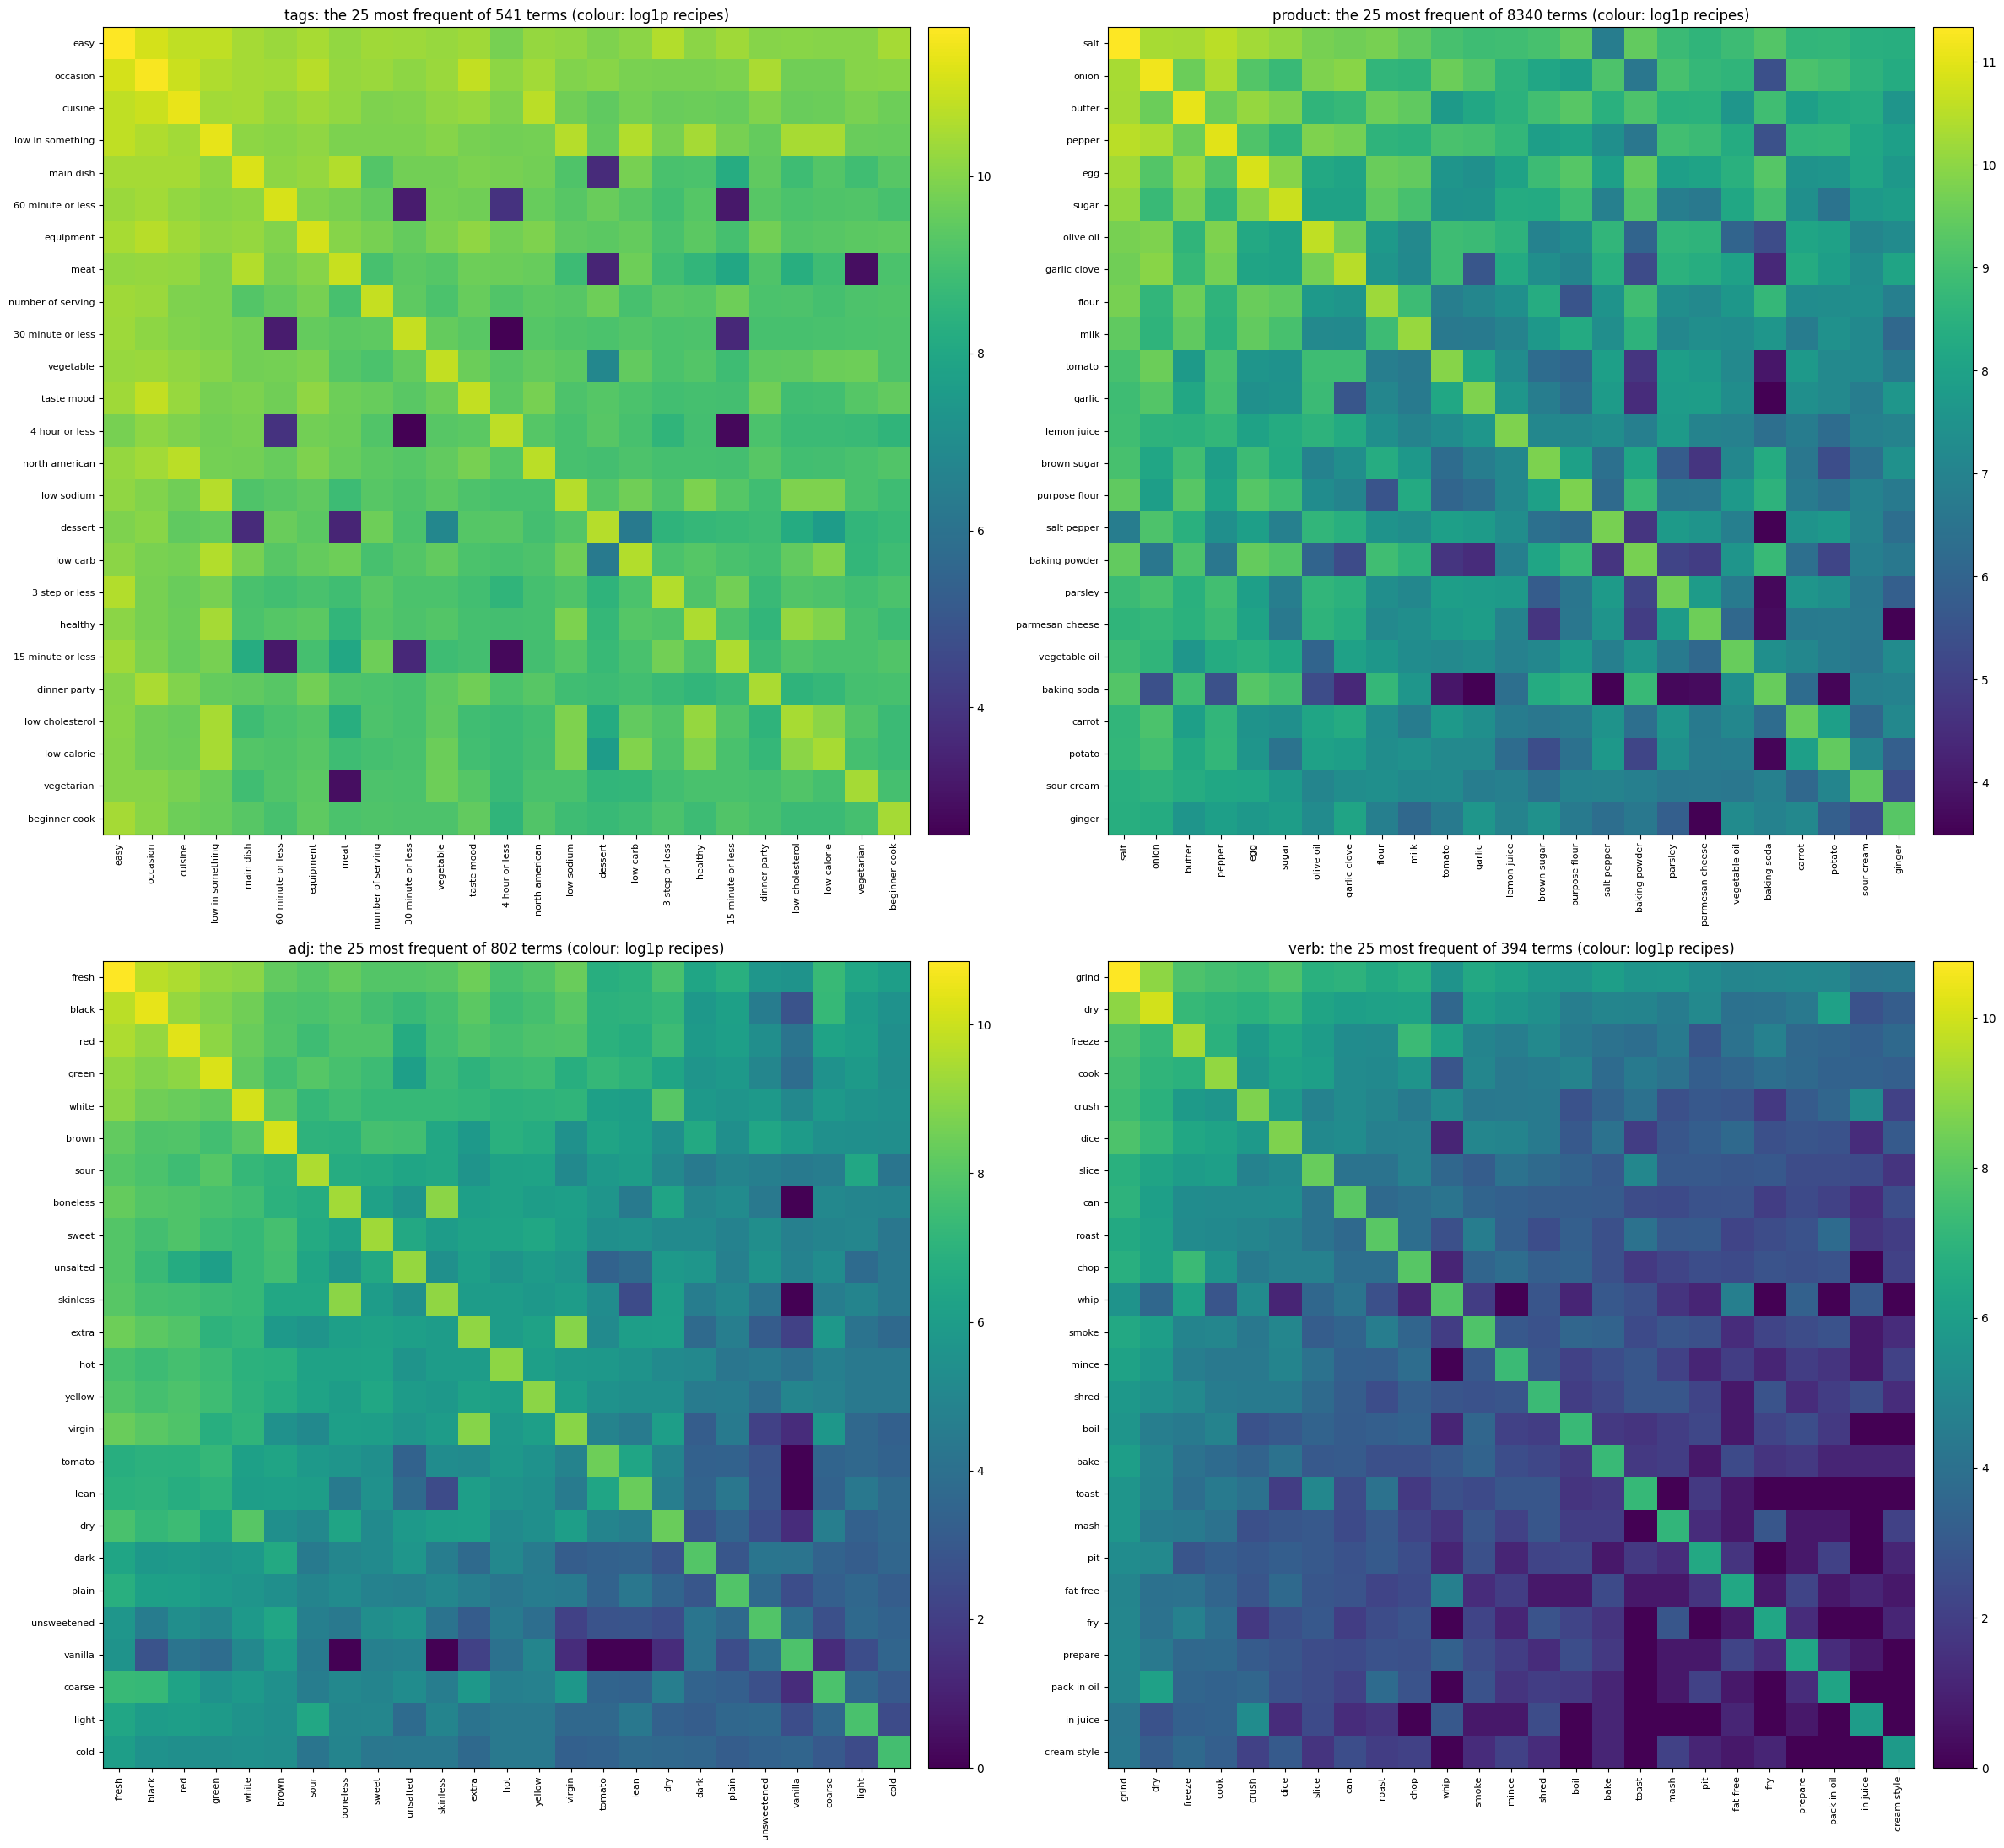

In [37]:
# co-occurrence of the terms of each kind: how many recipes carry both terms (the diagonal: how many carry the term).
# Terms are the normalized ones, counted once per recipe; tags_norm leaves the generic tags out.
from scipy import sparse
from sklearn.preprocessing import MultiLabelBinarizer

TOP_TERMS = 25   # the heatmaps show the most frequent terms of each kind
term_lists = {
    'tags': df['tags_norm'],
    'product': df['product_norm'],
    'adj': df['adj'].apply(lambda xs: uniq(norm_adj(a) for a in flat(xs))),
    'verb': df['verb'].apply(lambda xs: uniq(norm_verb(v) for v in flat(xs))),
}
cooc = {}   # kind -> (terms, sparse terms x terms co-occurrence counts)
for kind, lists in term_lists.items():
    mlb = MultiLabelBinarizer(sparse_output=True)
    X_terms = mlb.fit_transform(lists).astype(np.int32).tocsc()   # recipes x terms, 1 where the recipe has the term
    cooc[kind] = (mlb.classes_, (X_terms.T @ X_terms).tocsr())
    print(f'{kind:8s} {len(mlb.classes_):6d} terms')

def top_block(kind, k=TOP_TERMS):
    """The co-occurrence counts of the kind's k most frequent terms, as a DataFrame."""
    terms, C = cooc[kind]
    top = np.argsort(-C.diagonal())[:k]
    return pd.DataFrame(C[top][:, top].toarray(), index=terms[top], columns=terms[top])

fig, axes = plt.subplots(2, 2, figsize=(24, 22))
for ax, kind in zip(axes.ravel(), cooc):
    M = top_block(kind)
    im = ax.imshow(np.log1p(M.values), cmap='viridis')
    ax.set_xticks(range(len(M))); ax.set_xticklabels(M.columns, rotation=90, fontsize=8)
    ax.set_yticks(range(len(M))); ax.set_yticklabels(M.index, fontsize=8)
    ax.set_title(f'{kind}: the {len(M)} most frequent of {len(cooc[kind][0])} terms (colour: log1p recipes)')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.02)
plt.tight_layout()
plt.show()

In [38]:
# the pairs of different terms that most often appear in the same recipe, per kind
def top_pairs(kind, n=15):
    terms, C = cooc[kind]
    U = sparse.triu(C, k=1).tocoo()   # each pair once, without the diagonal
    order = np.argsort(-U.data)[:n]
    return pd.DataFrame({'term_a': terms[U.row[order]], 'term_b': terms[U.col[order]], 'recipes': U.data[order]})

for kind in cooc:
    print(kind)
    display(top_pairs(kind))

tags


,term_a,term_b,recipes
0,easy,occasion,65688
1,cuisine,occasion,56783
2,occasion,taste mood,50478
3,easy,low in something,49960
4,cuisine,easy,48917
5,cuisine,north american,46569
6,equipment,occasion,44738
7,low in something,low sodium,42361
8,main dish,meat,41518
9,low carb,low in something,41270


product


,term_a,term_b,recipes
0,pepper,salt,37460
1,onion,pepper,31865
2,onion,salt,29711
3,butter,salt,29506
4,egg,salt,28032
5,butter,egg,24112
6,salt,sugar,23456
7,garlic clove,onion,20848
8,egg,sugar,20371
9,olive oil,onion,18681


adj


,term_a,term_b,recipes
0,black,fresh,16580
1,fresh,red,13412
2,black,red,9291
3,fresh,green,8910
4,green,red,8130
5,boneless,skinless,7805
6,fresh,white,7781
7,extra,virgin,7381
8,black,green,6718
9,black,white,5024


verb


,term_a,term_b,recipes
0,dry,grind,7547
1,freeze,grind,2376
2,dice,grind,2324
3,cook,grind,1931
4,crush,grind,1696
5,chop,freeze,1514
6,dry,freeze,1332
7,dice,dry,1300
8,cook,dry,1154
9,can,grind,1049


In [39]:
# Positive pointwise mutual information of each pair of different terms that share a recipe, per kind:
# PPMI(a, b) = max(0, log2(p(a, b) / (p(a) p(b)))), p = share of recipes carrying the term(s). 0 = together no more
# often than chance (PMI <= 0 is clipped to 0), > 0 = together more often than chance. Pairs that never share a recipe
# (PPMI 0 by definition) are left out, or they would swamp the stats. A pair seen in only a recipe or two gets a large
# PMI from chance alone, so the stats are also given over pairs in MIN_PAIR_COUNT+ recipes.
MIN_PAIR_COUNT = 5

def pair_ppmi(kind, min_count=1):
    """The PPMI of every pair of the kind's terms found together in at least min_count recipes."""
    terms, C = cooc[kind]
    n = len(df)
    freq = C.diagonal()
    U = sparse.triu(C, k=1).tocoo()
    keep = U.data >= min_count
    rows, cols = U.row[keep], U.col[keep]
    # as floats: the counts are int32, and count * n overflows it
    together, freq = U.data[keep].astype(float), freq.astype(float)
    return np.maximum(np.log2(together * n / (freq[rows] * freq[cols])), 0)

ppmi_stats = pd.DataFrame([
    {'kind': kind, 'min_recipes': m, 'pairs': len(ppmi := pair_ppmi(kind, m)),
     'mean_ppmi': ppmi.mean(), 'median_ppmi': np.median(ppmi), 'share_positive': (ppmi > 0).mean()}
    for kind in cooc for m in (1, MIN_PAIR_COUNT)
]).set_index(['kind', 'min_recipes'])
ppmi_stats.round(3)

pairs  mean_ppmi  median_ppmi  share_positive
kind    min_recipes                                                
tags    1             71053      0.648        0.119           0.543
        5             48810      0.621        0.227           0.600
product 1            635701      2.163        1.471           0.763
        5            145493      1.219        0.811           0.720
adj     1             10070      1.857        1.057           0.740
        5              3059      1.058        0.566           0.722
verb    1              2144      2.664        1.412           0.820
        5               588      1.573        0.725           0.782

In [16]:
df[['name', 'product_norm', 'desc_norm']].head(8)

,name,product_norm,desc_norm
0,! Arriba ! Baked Winter Squash Mexican-Style,"[winter squash, mexican seasoning, mixed spice...",[]
1,"""A Bit Different"" Breakfast Pizza","[pizza, sausage patty, egg, milk, salt pepper,...",[prepare]
2,"""All in the Kitchen"" Chili","[beef, onion, tomato, tomato paste, soup, rote...","[yellow, tomato, grind, dice]"
3,"""Alouette"" Potatoes","[spreadable, cheese, garlic, herb, new potato,...","[red, yellow]"
4,"""Amish"" tomato ketchup, for canning","[tomato juice, apple cider vinegar, sugar, sal...",[]
5,"""AWW"" Marinated Olives","[fennel seed, olive, garlic, peppercorn, orang...","[green, ripe, red, extra, virgin]"
6,"""Backyard-Style"" Barbecued Ribs","[pork sparerib, soy sauce, garlic, ginger, chi...","[fresh, coarse, black, tomato, brown, yellow, ..."
7,"""Beat This"" Banana Bread","[sugar, butter, banana, egg, lemon juice, oran...","[unsalted, fresh]"


## 2. Price interval (±3 per unpriced item)

`total_price` is already the sum of the priced ingredients (from `price_breakdown`); `unpriced_items` lists the rest.

In [17]:
def add_price_interval(frame):
    frame['n_unpriced'] = frame['unpriced_items'].str.len()
    frame['price_mid'] = frame['total_price'].astype(float)
    frame['price_lo'] = (frame['price_mid'] - UNPRICED_BAND * frame['n_unpriced']).clip(lower=0)
    frame['price_hi'] = frame['price_mid'] + UNPRICED_BAND * frame['n_unpriced']
    return frame

df = add_price_interval(df)
df[['price_mid', 'price_lo', 'price_hi', 'n_unpriced']].describe().round(2)

,price_mid,price_lo,price_hi,n_unpriced
count,218691.00,218691.00,218691.00,218691.00
mean,29.23,16.90,42.87,4.55
std,20.34,19.18,22.60,2.47
min,0.00,0.00,3.00,0.00
25%,16.21,2.70,27.90,3.00
50%,25.72,12.66,39.46,4.00
75%,37.57,24.50,53.06,6.00
max,425.99,404.99,446.99,25.00


## 3. Embeddings (embed each unique token once, then mean-pool per recipe)

In [ ]:
encoder = SentenceTransformer(ENCODER_NAME, device='cpu')
dim = encoder.get_sentence_embedding_dimension()
tok2vec = {}

def encode(tokens):
    new = sorted({t for t in tokens if t not in tok2vec})
    if new:
        vecs = encoder.encode(new, batch_size=64, normalize_embeddings=True, show_progress_bar=len(new) > 256)
        tok2vec.update(zip(new, vecs))

def pool(tokens):
    if not tokens:
        return np.zeros(dim, dtype=np.float32)
    v = np.mean([tok2vec[t] for t in tokens], axis=0)
    return v / (np.linalg.norm(v) + 1e-9)

EMBEDDED = ['product_norm', 'desc_norm', 'tags_norm']

def embed(frame):
    # one pooled embedding per column of EMBEDDED, in that order
    encode([t for col in EMBEDDED for xs in frame[col] for t in xs])
    return tuple(np.stack(frame[col].apply(pool)) for col in EMBEDDED)

E_product, E_desc, E_tags = embed(df)
E_product.shape, E_desc.shape, E_tags.shape

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Batches:   0%|          | 0/144 [00:00<?, ?it/s]

((218691, 1024), (218691, 1024))

## 4. Feature blocks + weighting

In [19]:
# per-block transforms are kept so new recipes can be projected into the same space
nutr_medians = df[NUTRIENTS].median()
block_fits = {}   # name -> (PCA or None, StandardScaler)

def raw_blocks(frame, E_product, E_desc, E_tags):
    return {
        'product': E_product,
        'adj_verb': E_desc,
        'tags': E_tags,
        'nutrients': np.log1p(frame[NUTRIENTS].fillna(nutr_medians).values),
        'price': np.log1p(frame[['price_lo', 'price_hi']].values),
    }

def fit_blocks(raw):
    for name, R in raw.items():
        pca = PCA(n_components=PCA_DIMS[name], random_state=SEED).fit(R) if name in PCA_DIMS else None
        block_fits[name] = (pca, StandardScaler().fit(pca.transform(R) if pca else R))

def assemble(raw):
    # PCA (for embeddings) -> standardize -> scale to unit total variance -> block weight
    out = []
    for name, R in raw.items():
        pca, scaler = block_fits[name]
        Z = scaler.transform(pca.transform(R) if pca else R)
        out.append(Z / np.sqrt(Z.shape[1]) * WEIGHTS[name])
    return np.hstack(out)

raw = raw_blocks(df, E_product, E_desc, E_tags)
fit_blocks(raw)
X = assemble(raw)
for name, R in raw.items():
    print(f'{name:10s} dims={PCA_DIMS.get(name, R.shape[1]):3d} weight={WEIGHTS[name]}')
X.shape

product    dims= 32 weight=1.5
adj_verb   dims= 16 weight=1.0
nutrients  dims=  7 weight=1.0
price      dims=  2 weight=1.0


(218691, 57)

## 5. UMAP + HDBSCAN

In [20]:
umap10 = umap.UMAP(n_components=10, n_neighbors=30, min_dist=0.0, random_state=SEED)
X10 = umap10.fit_transform(X)
X2 = umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.1, random_state=SEED).fit_transform(X)

hdb = HDBSCAN(min_cluster_size=40, min_samples=10, cluster_selection_method='eom')
labels = hdb.fit_predict(X10)
df['cluster'] = labels
df['membership'] = hdb.probabilities_

n_clusters = labels.max() + 1
n_noise = (labels == -1).sum()
print(f'{n_clusters} clusters, {n_noise} outliers ({n_noise / len(df):.1%})')

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


300 clusters, 124480 outliers (56.9%)


## 6. Cluster names (top product tokens)

In [21]:
def top_tokens(sub, k=3):
    return ', '.join(pd.Series([t for xs in sub['product_norm'] for t in xs]).value_counts().index[:k])

summary = (df[df.cluster >= 0].groupby('cluster')
           .agg(size=('recipe_id', 'size'),
                price_mid=('price_mid', 'median'),
                energy_kcal=('energy_kcal', 'median'),
                protein_g=('protein_g', 'median'),
                fat_g=('fat_g', 'median'),
                carb_g=('carb_g', 'median')))
summary['top_products'] = [top_tokens(df[df.cluster == c]) for c in summary.index]
summary['top_desc'] = [', '.join(pd.Series([t for xs in df[df.cluster == c]['desc_norm'] for t in xs]).value_counts().index[:3])
                       for c in summary.index]
summary.sort_values('size', ascending=False).round(2)

,size,price_mid,energy_kcal,protein_g,fat_g,carb_g,top_products,top_desc
cluster,,,,,,,,
244,7145,33.62,138.47,11.86,5.14,6.82,"chicken breast, pepper, onion","boneless, skinless, fresh"
63,2850,31.01,149.26,5.79,7.84,7.50,"olive oil, salt, garlic clove","fresh, brown, low sodium"
241,2345,25.95,356.31,4.62,16.15,45.18,"egg, sugar, butter","green, sift, thick"
2,2183,22.88,173.40,5.56,6.78,11.36,"salt, butter, onion","dry, cold, white"
272,2179,33.20,114.27,1.57,5.46,8.11,"olive oil, onion, pepper","fresh, red, black"
...,...,...,...,...,...,...,...,...
15,40,17.44,55.07,2.62,2.96,4.43,"sesame seed, sesame oil, soy sauce","toast, fresh, dark"
58,40,17.10,169.64,1.95,9.96,19.05,"sour cream, cream cheese, sugar","sour, fresh, brown"
127,40,17.88,688.58,0.00,70.12,0.00,"butter, lemon juice, lemon","rind, rind of, green"


## 7. Cluster map with boundaries and outliers

Clustering happens in 10-d, so one cluster can appear as several islands in this 2-d view.
Boundaries: a 15-NN classifier is fitted on the clustered (non-noise) 2-d points. Each grid cell is shaded by the predicted cluster, and black lines are drawn wherever neighbouring cells disagree. Cells far from any point are left blank.
Grey × = HDBSCAN outliers (label -1). Point size scales with membership probability. The right panel zooms in on the dense centre.

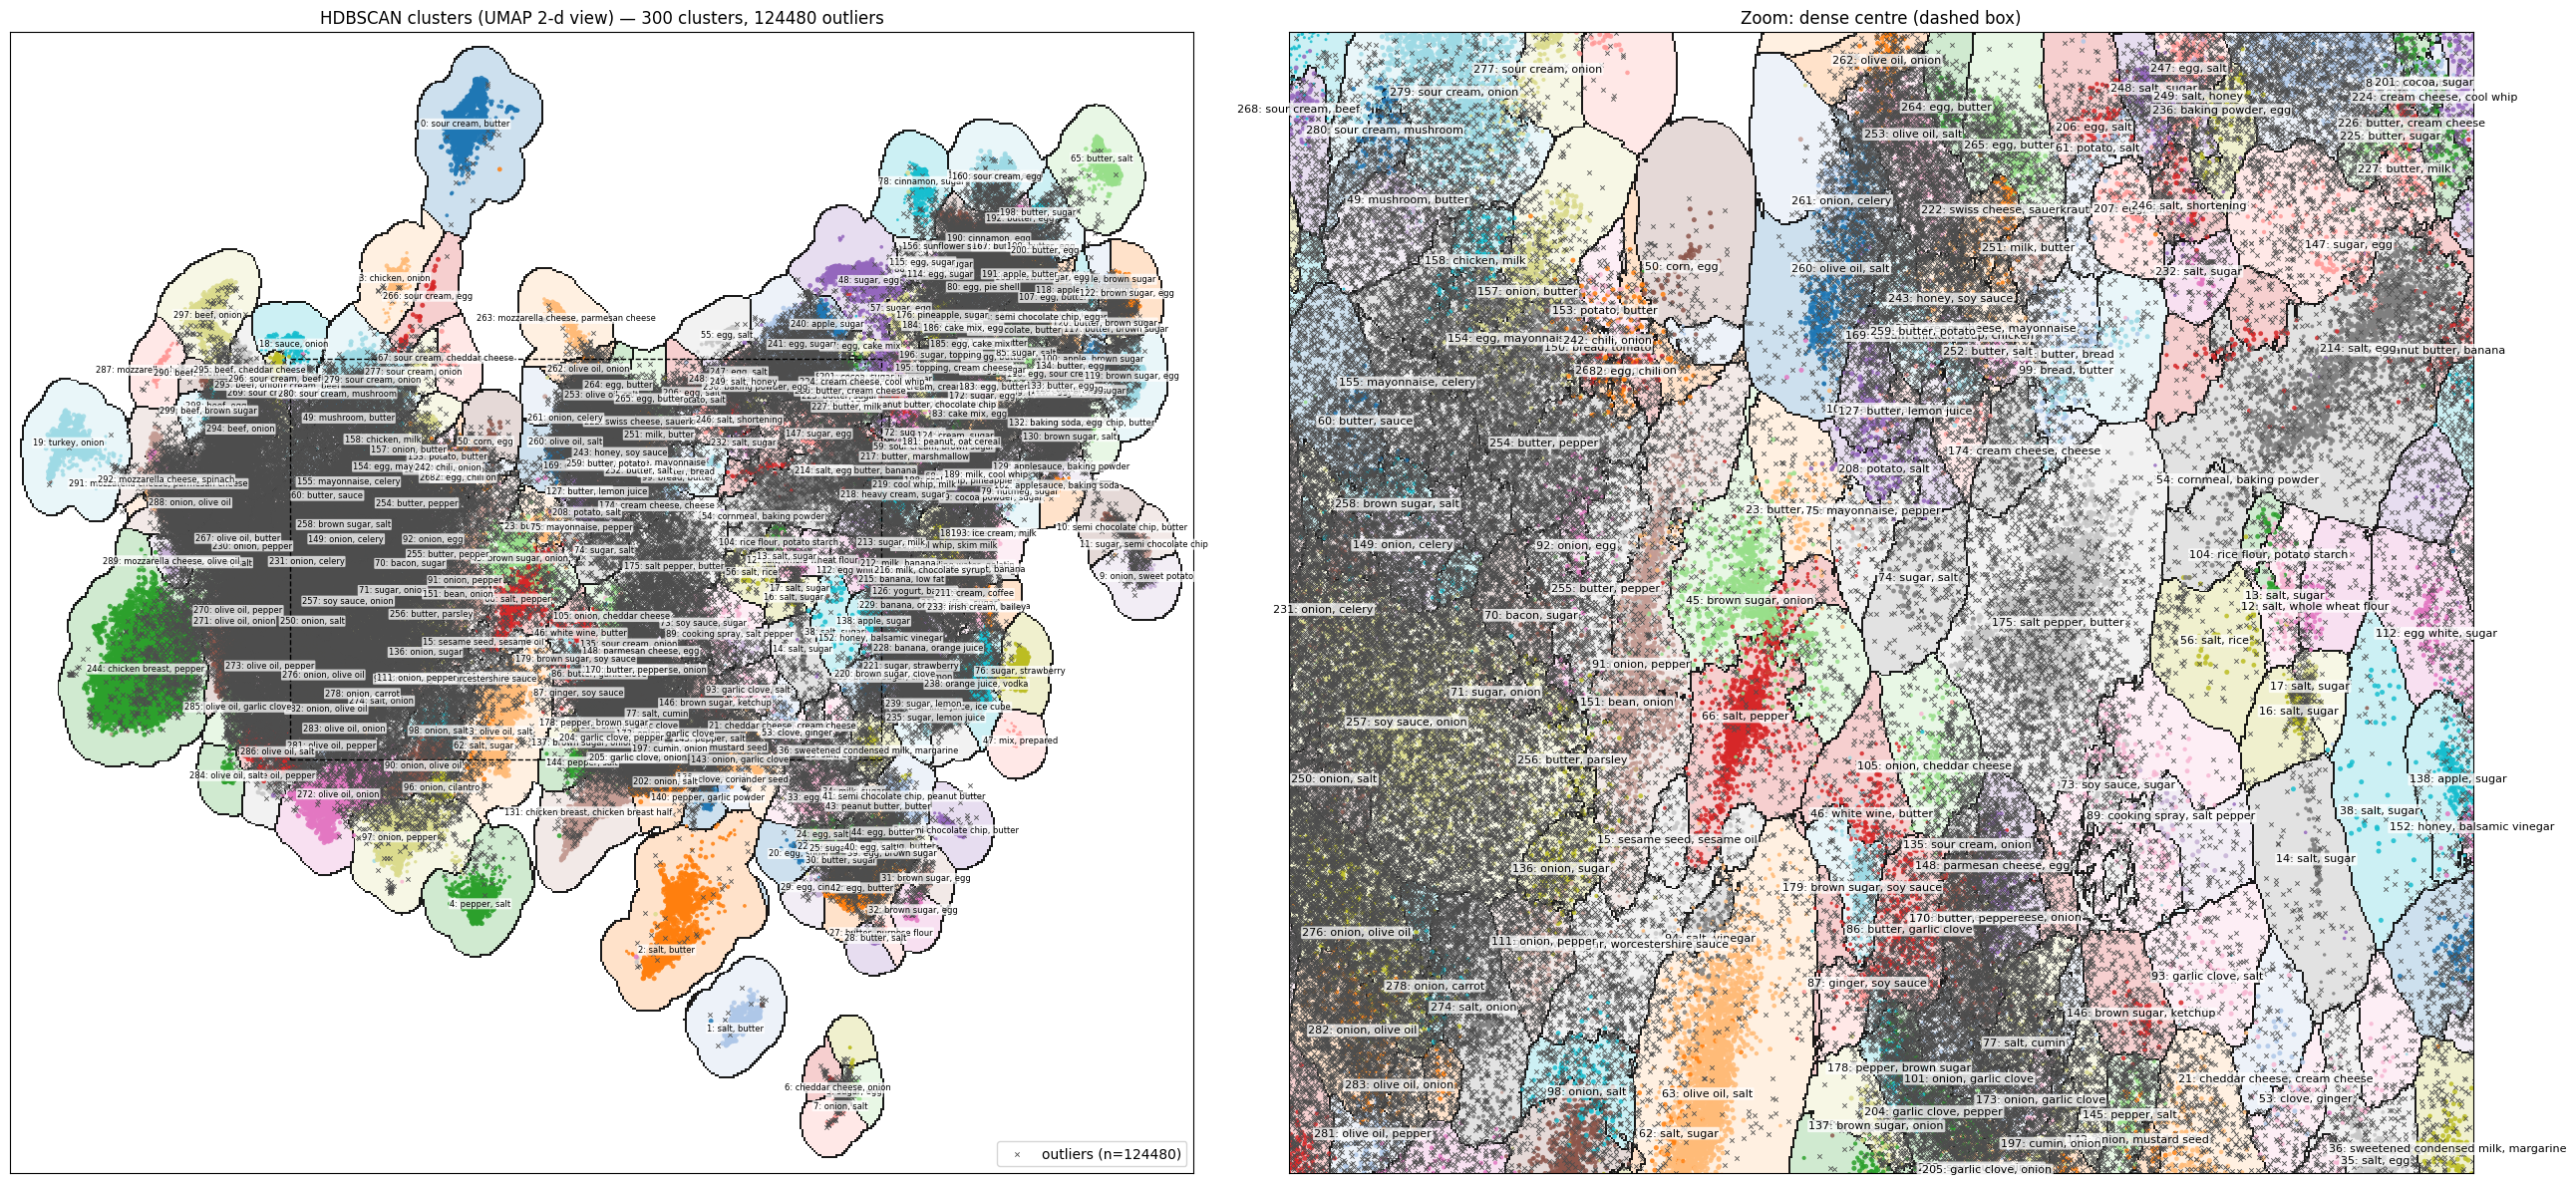

In [22]:
cmap = plt.get_cmap('tab20')
colors = {c: cmap(c % 20) for c in range(n_clusters)}
mask = labels >= 0

knn = KNeighborsClassifier(n_neighbors=15).fit(X2[mask], labels[mask])

def region_grid(xlim, ylim, res=600, max_dist=0.35):
    xx, yy = np.meshgrid(np.linspace(*xlim, res), np.linspace(*ylim, res))
    grid = np.c_[xx.ravel(), yy.ravel()]
    zz = knn.predict(grid).reshape(xx.shape)
    dist, _ = knn.kneighbors(grid, n_neighbors=1)
    zz = np.where(dist.reshape(xx.shape) < max_dist, zz, -1)
    # boundary = cell whose label differs from its right/upper neighbour (and is not empty on both sides)
    edge = np.zeros_like(zz, dtype=bool)
    edge[:, :-1] |= (zz[:, :-1] != zz[:, 1:]) & ((zz[:, :-1] >= 0) | (zz[:, 1:] >= 0))
    edge[:-1, :] |= (zz[:-1, :] != zz[1:, :]) & ((zz[:-1, :] >= 0) | (zz[1:, :] >= 0))
    return zz, edge

def medoid(P):
    c = np.median(P, axis=0)
    return P[np.argmin(((P - c) ** 2).sum(1))]     # always lands on a real point

cluster_names = {c: top_tokens(df[df.cluster == c], 2) for c in range(n_clusters)}
region_cmap = plt.matplotlib.colors.ListedColormap([colors[c] for c in range(n_clusters)])

def draw_map(ax, xlim, ylim, fontsize):
    zz, edge = region_grid(xlim, ylim)
    ext = (*xlim, *ylim)
    ax.imshow(np.ma.masked_less(zz, 0), origin='lower', extent=ext, cmap=region_cmap,
              vmin=-0.5, vmax=n_clusters - 0.5, alpha=0.22, aspect='auto', interpolation='nearest')
    ax.imshow(np.ma.masked_where(~edge, edge), origin='lower', extent=ext, cmap='binary',
              vmin=0, vmax=1, alpha=0.9, aspect='auto', interpolation='nearest')
    ax.scatter(X2[mask, 0], X2[mask, 1], c=[colors[l] for l in labels[mask]],
               s=3 + 10 * df['membership'].values[mask], alpha=0.85, linewidths=0)
    ax.scatter(X2[~mask, 0], X2[~mask, 1], marker='x', c='0.3', s=10, linewidths=0.6, label=f'outliers (n={n_noise})')
    for c in range(n_clusters):
        mx, my = medoid(X2[labels == c])
        if xlim[0] < mx < xlim[1] and ylim[0] < my < ylim[1]:
            ax.text(mx, my, f'{c}: {cluster_names[c]}', fontsize=fontsize, ha='center', va='center',
                    bbox=dict(boxstyle='round,pad=0.12', fc='white', ec='none', alpha=0.75))
    ax.set_xlim(xlim); ax.set_ylim(ylim); ax.set_xticks([]); ax.set_yticks([])

pad = 0.5
full = ((X2[:, 0].min() - pad, X2[:, 0].max() + pad), (X2[:, 1].min() - pad, X2[:, 1].max() + pad))
lo, hi = np.percentile(X2, 30, axis=0), np.percentile(X2, 70, axis=0)
zoom = ((lo[0] - 1, hi[0] + 1), (lo[1] - 1, hi[1] + 1))

fig, axes = plt.subplots(1, 2, figsize=(26, 12), gridspec_kw={'width_ratios': [1, 1]})
draw_map(axes[0], *full, fontsize=6)
axes[0].add_patch(plt.Rectangle((zoom[0][0], zoom[1][0]), zoom[0][1] - zoom[0][0], zoom[1][1] - zoom[1][0],
                                fill=False, ls='--', ec='k'))
axes[0].set_title(f'HDBSCAN clusters (UMAP 2-d view) — {n_clusters} clusters, {n_noise} outliers')
axes[0].legend(loc='lower right')
draw_map(axes[1], *zoom, fontsize=8)
axes[1].set_title('Zoom: dense centre (dashed box)')
plt.tight_layout()
plt.show()

## 8. Outliers

Where the outliers sit and how strongly the clustered points belong to their clusters, followed by a sample of outlier recipes.

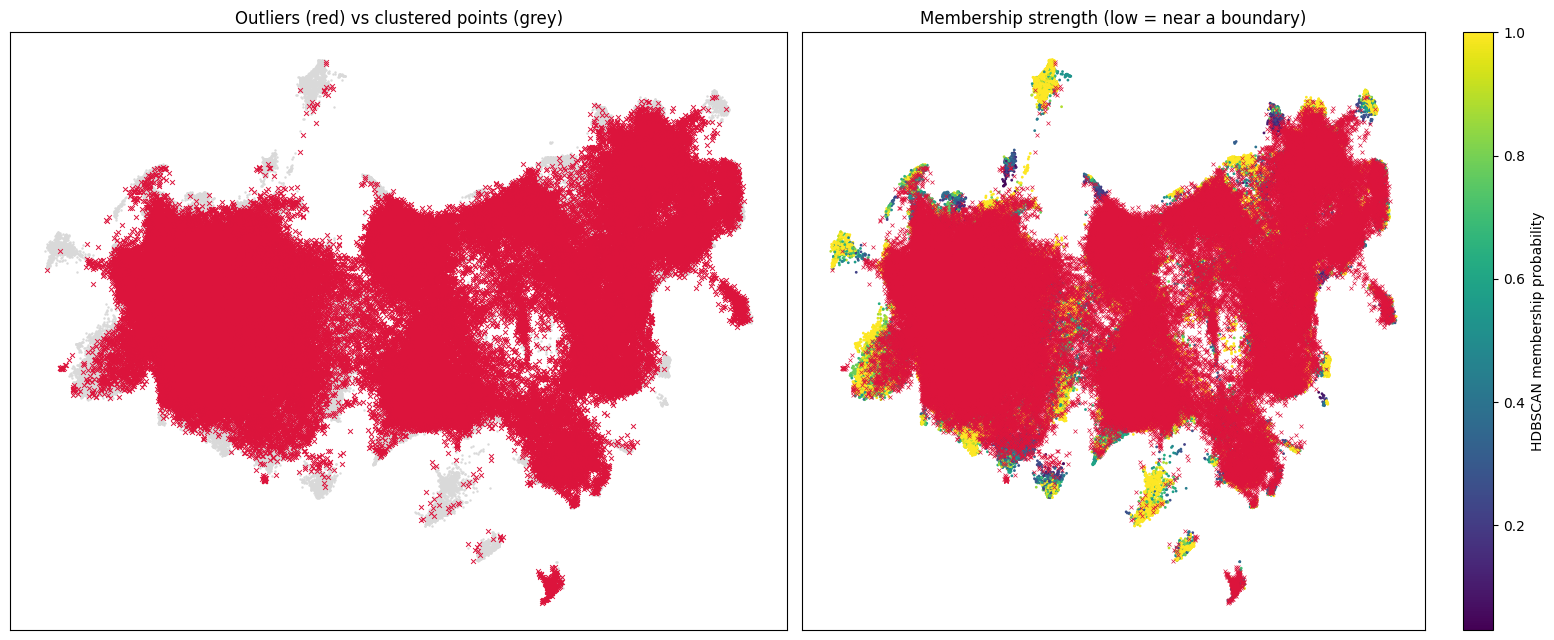

124480 outliers; share with unpriced items: 98.6% (vs 98.6% overall)


,name,product_norm,desc_norm,price_lo,price_hi,energy_kcal,protein_g,fat_g
112255,Krispies,"[purpose flour, salt, baking soda, dark sugar,...","[brown, salted, chocolate]",0.00,36.61,345.555556,3.703704,14.444444
60515,Crema De Fruta,"[ladyfinger, fruit cocktail, sugar, flour, egg...","[white, unflavored]",18.38,54.38,244.661017,7.768362,4.590395
119213,Low Fat Banana Bread,"[purpose flour, splenda, baking powder, baking...","[granular, grind]",3.19,33.19,192.553191,5.319149,0.000000
18381,Be-Deviled Pork Buns,"[pork, beer, onion, garlic clove, cumin, peppe...","[red, dill, yellow, grind]",10.57,46.57,238.564356,16.584158,12.549505
217935,Zrazy Zawijane (polish Beef Roulade in Sour Cr...,"[butter, vegetable oil, onion, mushroom, bread...","[unsalted, soft, sour]",17.01,47.01,120.259146,8.993902,7.728659
139647,One Pot Sweet and Peppery Noodle Kugel,"[egg noodle, brown sugar, pepper, salt, egg, oil]","[brown, black]",24.83,36.83,162.624585,3.322259,5.398671
48959,Chocolate Swirl Bread,"[flour, yeast, milk, sugar, butter, salt, egg,...",[],21.44,45.44,167.809111,3.073030,5.216920
204892,Tropical Tartar Sauce,"[mayonnaise, jalapeno, pickle, caper, olive, c...","[green, fresh]",1.95,43.95,841.208791,2.747253,71.428571
153016,Polish Sausage and Kraut,"[polish sausage, butter, sauerkraut, tomato, c...","[unsalted, juice, green, brown, dice, with jui...",30.53,54.53,145.275779,5.515588,11.378897
91535,Greek Style Spaghetti Squash Salad,"[wine vinegar, balsamic vinegar, olive oil, or...","[red, extra, virgin, fresh, black, green, dry,...",23.69,71.69,71.638889,2.638889,2.347222


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

ax = axes[0]
ax.scatter(X2[mask, 0], X2[mask, 1], c='0.85', s=3, linewidths=0)
ax.scatter(X2[~mask, 0], X2[~mask, 1], c='crimson', marker='x', s=12, linewidths=0.7)
ax.set_title('Outliers (red) vs clustered points (grey)')
ax.set_xticks([]); ax.set_yticks([])

ax = axes[1]
sc = ax.scatter(X2[mask, 0], X2[mask, 1], c=df['membership'][mask], cmap='viridis', s=4, linewidths=0)
ax.scatter(X2[~mask, 0], X2[~mask, 1], c='crimson', marker='x', s=8, linewidths=0.5)
plt.colorbar(sc, ax=ax, label='HDBSCAN membership probability')
ax.set_title('Membership strength (low = near a boundary)')
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

outliers = df[df.cluster == -1]
print(f'{len(outliers)} outliers; share with unpriced items: {(outliers.n_unpriced > 0).mean():.1%} '
      f'(vs {(df.n_unpriced > 0).mean():.1%} overall)')
outliers[['name', 'product_norm', 'desc_norm', 'price_lo', 'price_hi', 'energy_kcal', 'protein_g', 'fat_g']].sample(20, random_state=SEED)

## 9. Price interval and nutrients by cluster

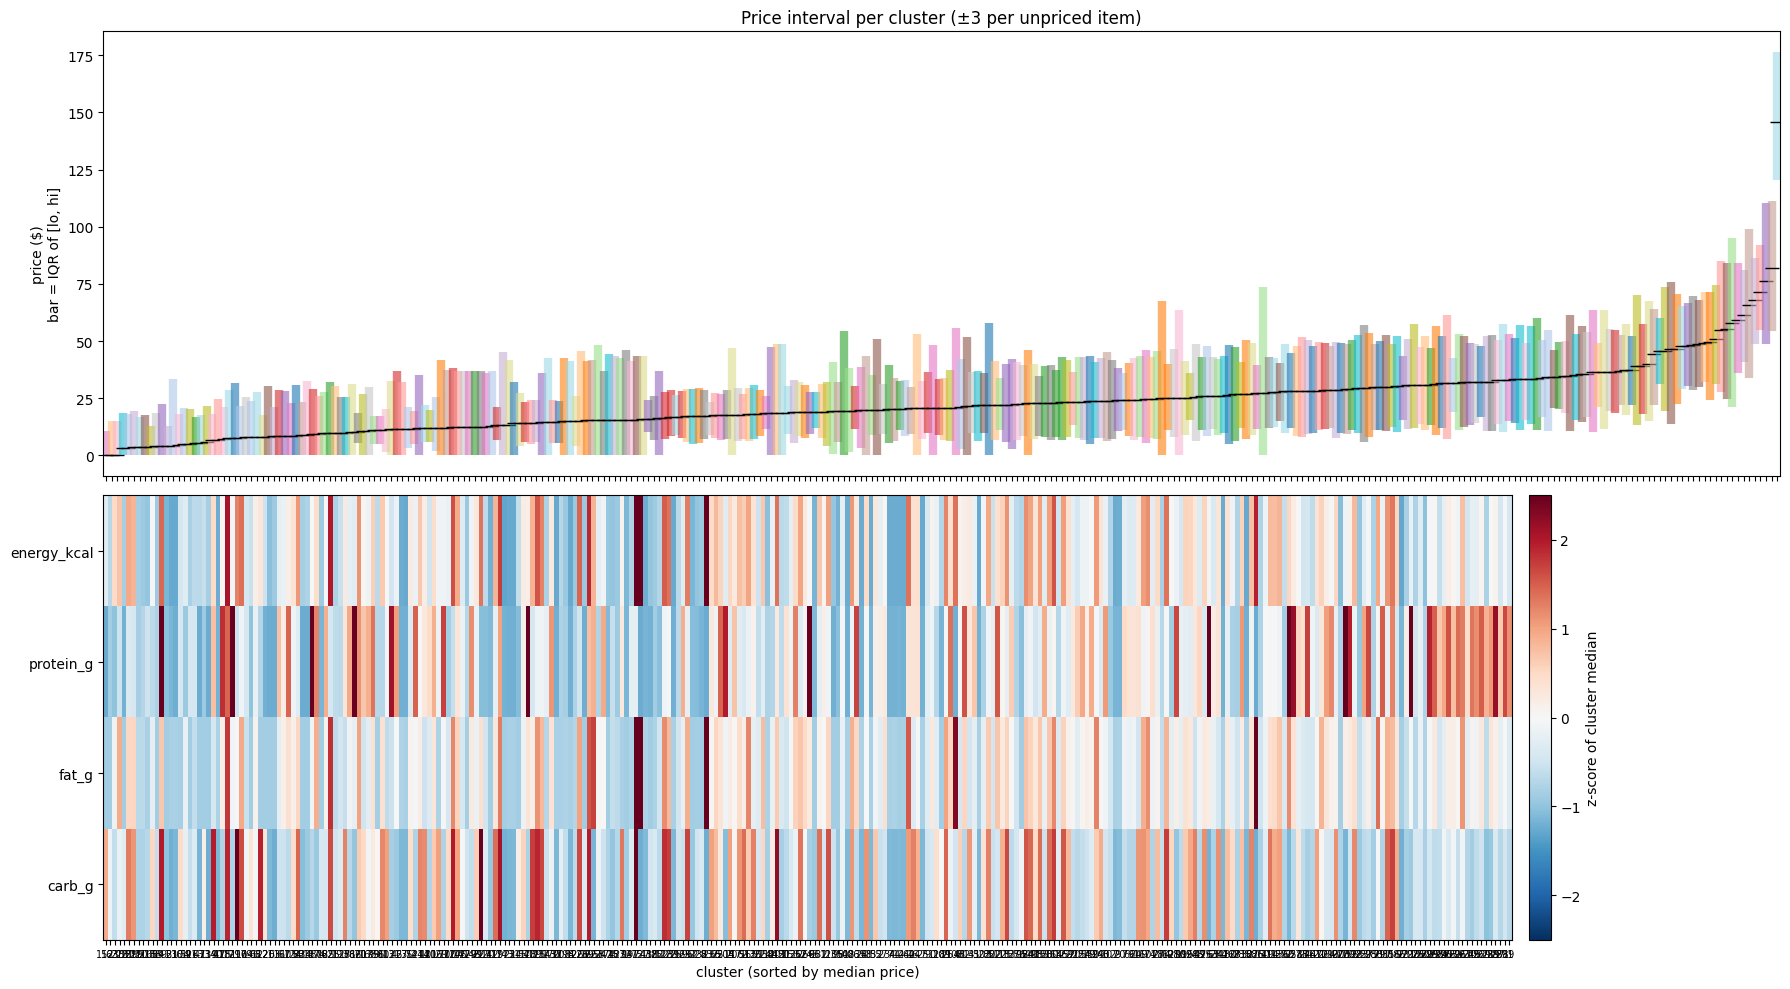

In [24]:
order = summary.sort_values('price_mid').index
fig, axes = plt.subplots(2, 1, figsize=(18, 10), sharex=True)

ax = axes[0]
for i, c in enumerate(order):
    sub = df[df.cluster == c]
    ax.vlines(i, sub['price_lo'].quantile(0.25), sub['price_hi'].quantile(0.75), color=colors[c], linewidth=6, alpha=0.6)
    ax.plot(i, sub['price_mid'].median(), 'k_', markersize=10)
ax.set_ylabel('price ($)\nbar = IQR of [lo, hi]')
ax.set_title('Price interval per cluster (±3 per unpriced item)')

ax = axes[1]
z = summary.loc[order, ['energy_kcal', 'protein_g', 'fat_g', 'carb_g']]
z = (z - z.mean()) / z.std()
im = ax.imshow(z.T.values, aspect='auto', cmap='RdBu_r', vmin=-2.5, vmax=2.5)
ax.set_yticks(range(z.shape[1])); ax.set_yticklabels(z.columns)
ax.set_xticks(range(len(order))); ax.set_xticklabels(order, fontsize=7)
ax.set_xlabel('cluster (sorted by median price)')
plt.colorbar(im, ax=ax, label='z-score of cluster median', pad=0.01)
plt.tight_layout(); plt.show()

## 10. Price vs energy, coloured by cluster (error bars = unpriced uncertainty)

/var/folders/7m/qbnvltn907d5bbyzc96qdyyw0000gp/T/ipykernel_99802/3992981687.py:10: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  ax.legend(); plt.tight_layout(); plt.show()
/Users/tung/Library/Python/3.12/lib/python/site-packages/IPython/core/pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


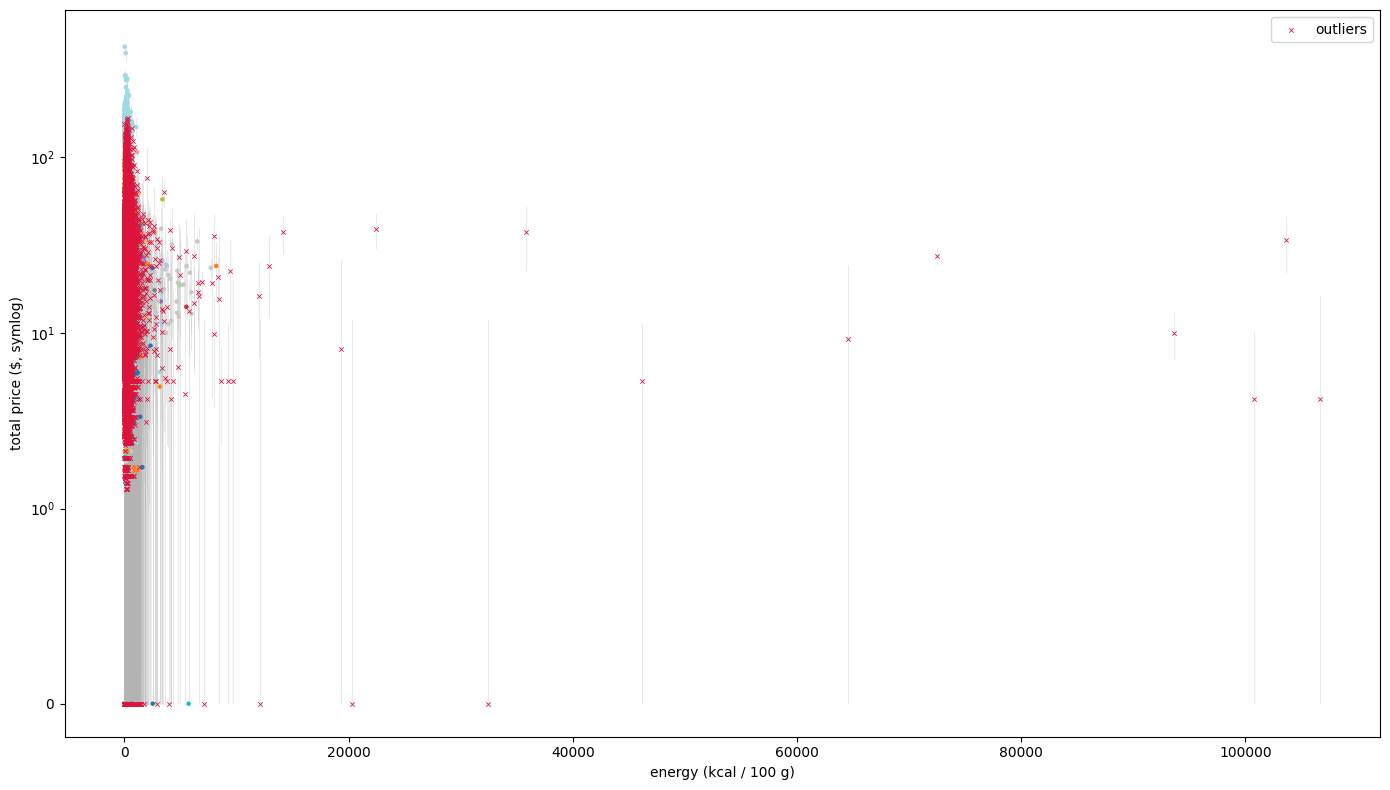

In [25]:
fig, ax = plt.subplots(figsize=(14, 8))
unc = df['n_unpriced'] > 0
ax.errorbar(df.loc[unc, 'energy_kcal'], df.loc[unc, 'price_mid'],
            yerr=[df.loc[unc, 'price_mid'] - df.loc[unc, 'price_lo'], df.loc[unc, 'price_hi'] - df.loc[unc, 'price_mid']],
            fmt='none', ecolor='0.7', elinewidth=0.4, alpha=0.5, zorder=1)
ax.scatter(df.loc[mask, 'energy_kcal'], df.loc[mask, 'price_mid'], c=[colors[l] for l in labels[mask]], s=5, zorder=2)
ax.scatter(df.loc[~mask, 'energy_kcal'], df.loc[~mask, 'price_mid'], marker='x', c='crimson', s=10, linewidths=0.6, zorder=3, label='outliers')
ax.set_yscale('symlog', linthresh=1)
ax.set_xlabel('energy (kcal / 100 g)'); ax.set_ylabel('total price ($, symlog)')
ax.legend(); plt.tight_layout(); plt.show()

## 11. Save the clustering model for inference

sklearn's `HDBSCAN` has no `predict()` for unseen points, so the saved bundle holds the whole fitted pipeline (normalized-token embedding cache, per-block PCA/scalers, nutrient medians, 10-d UMAP, the fitted `HDBSCAN`) plus a nearest-neighbour index over the training points in 10-d UMAP space.

A new recipe goes through the same features → `umap10.transform` steps. It then takes the majority label of its 15 nearest training points; noise points (-1) take part in the vote, so a recipe that lands in a noise region becomes an outlier. A recipe is also marked -1 when its nearest clustered training point is farther away than the 99th percentile of training nearest-neighbour distances.

In [26]:
K_ASSIGN = 15
nn_all = NearestNeighbors(n_neighbors=K_ASSIGN).fit(X10)
nn_clustered = NearestNeighbors(n_neighbors=2).fit(X10[labels >= 0])
# distance from each clustered point to its nearest *other* clustered point
d_self, _ = nn_clustered.kneighbors(X10[labels >= 0])
outlier_dist = float(np.percentile(d_self[:, 1], 99))

bundle = {
    'config': {'SEED': SEED, 'UNPRICED_BAND': UNPRICED_BAND, 'NUTRIENTS': NUTRIENTS, 'WEIGHTS': WEIGHTS,
               'PCA_DIMS': PCA_DIMS, 'ENCODER_NAME': ENCODER_NAME, 'K_ASSIGN': K_ASSIGN,
               'FOODCOM_NUTRIENTS': FOODCOM_NUTRIENTS,
               'GENERIC_TAG_SHARE': GENERIC_TAG_SHARE},
    'tok2vec': tok2vec,
    'nutr_medians': nutr_medians,
    'generic_tags': generic_tags,
    'block_fits': block_fits,
    'umap10': umap10,
    'hdbscan': hdb,
    'train_labels': labels,
    'train_recipe_id': df['recipe_id'].values,
    'nn_all': nn_all,
    'nn_clustered': nn_clustered,
    'outlier_dist': outlier_dist,
    'cluster_names': cluster_names,
}
os.makedirs(ARTIFACT_DIR, exist_ok=True)
model_path = f'{ARTIFACT_DIR}/recipe_clustering.joblib'
joblib.dump(bundle, model_path, compress=3)

with open(model_path, 'rb') as f:
    sha = hashlib.sha256(f.read()).hexdigest()
meta = {'n_clusters': int(n_clusters), 'n_outliers': int(n_noise), 'n_train': len(df),
        'outlier_dist': outlier_dist, 'sha256': sha, 'cluster_names': {int(k): v for k, v in cluster_names.items()}}
with open(f'{ARTIFACT_DIR}/meta.json', 'w') as f:
    json.dump(meta, f, indent=2)
print(f'saved {model_path} ({os.path.getsize(model_path) / 1e6:.1f} MB), sha256={sha[:12]}')

saved model_artifacts/recipe_clustering_foodcom/recipe_clustering.joblib (359.5 MB), sha256=91e6334be14f


## 12. Inference

`predict_clusters` needs the helper functions from sections 1–4 (`parse_lists`, `add_nutrients`, `normalize_tokens`, `add_price_interval`, `embed`, `raw_blocks`, `assemble`). It loads their fitted state from the bundle, so the training cells in sections 5–10 don't have to run. Tokens not seen in training are encoded on the fly. The sanity check at the end re-predicts training recipes and compares them with their HDBSCAN labels. `umap.transform` is not bit-identical to `fit_transform`, so expect high but not perfect agreement.

In [27]:
def load_clustering(path=f'{ARTIFACT_DIR}/recipe_clustering.joblib'):
    global nutr_medians, block_fits, generic_tags
    b = joblib.load(path)
    tok2vec.update(b['tok2vec'])
    nutr_medians, block_fits, generic_tags = b['nutr_medians'], b['block_fits'], b['generic_tags']
    return b

def predict_clusters(frame, b):
    """frame: rows with the columns of foodcom_recipes.csv (list columns may be strings).
    Returns frame with `cluster` (-1 = outlier) and `cluster_name`."""
    frame = add_price_interval(normalize_tokens(add_nutrients(parse_lists(frame))))
    Z = b['umap10'].transform(assemble(raw_blocks(frame, *embed(frame))))

    _, idx = b['nn_all'].kneighbors(Z)
    votes = b['train_labels'][idx]
    pred = np.array([np.bincount(v + 1).argmax() - 1 for v in votes])   # +1 shift so -1 can vote
    d_near, _ = b['nn_clustered'].kneighbors(Z, n_neighbors=1)
    pred[d_near[:, 0] > b['outlier_dist']] = -1

    frame['cluster'] = pred
    frame['cluster_name'] = [b['cluster_names'].get(c, 'outlier') for c in pred]
    return frame

clustering = load_clustering()
sample = pd.read_csv('../../input_stage2/foodcom_recipes.csv').sample(500, random_state=SEED)
pred = predict_clusters(sample, clustering)
truth = df.set_index('recipe_id').loc[pred['recipe_id'], 'cluster'].values
print(f'agreement with training labels on {len(pred)} recipes: {(pred["cluster"].values == truth).mean():.1%}')
pred[['name', 'cluster', 'cluster_name']].head(10)

agreement with training labels on 500 recipes: 89.2%


,name,cluster,cluster_name
109061,Jolly Cheddar Cheese Spread,175,"salt pepper, butter"
208806,Vegan Cream of Asparagus Soup,-1,outlier
214829,Wildfire Horseradish Crusted Pork Chops,-1,outlier
169774,Sambusa,97,"onion, pepper"
5058,Angel Hair Pasta W/ Lemon &amp; Chicken,-1,outlier
181576,South Texas Spanish Rice,66,"salt, pepper"
56310,Crab and White Wine Pasta,-1,outlier
10655,Avocado With Alfalfa,272,"olive oil, onion"
20013,Beer Barbecue Sauce,95,"brown sugar, worcestershire sauce"
511,&quot;special&quot; Oatmeal Cookies ( Vegan ),-1,outlier


In [30]:
df.drop(columns=['price_breakdown']).to_csv('../../output/recipe_clusters_foodcom.csv', index=False)